# Cohortes fuera de tiempo: PD de pymes por cosecha a través de 2008 (C03)

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 03 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- explicar por qué un panel de créditos se valida por cosecha, fuera del tiempo, y por qué el objetivo de una cosecha solo puede leerse en su marca de 5 años;
- leer las cinco ventanas móviles de entrenamiento de C03 y verificar, con fechas, que cada una cierra antes de que se apruebe su cohorte de prueba;
- leer la PD a 5 años observada y predicha de quince años de aprobación, las curvas acumuladas por mes y la calibración por decil;
- recalcular con el motor las filas de portafolio de la batería de cada cohorte, y explicar por qué las pruebas de nivel unilaterales siguen en verde mientras la tarjeta de puntaje sobrepredice el riesgo.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La siguiente celda importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

El caso C03 es la PD de créditos a pequeñas empresas por cosecha. Los datos son el archivo FOIA de créditos 7(a) de la Administración de Pequeños Negocios de EE. UU. (dueño: U.S. SBA; licencia "U.S. Government Works", clase `mirror-allowed`; https://data.sba.gov/dataset/7a-504-foia; créditos aprobados desde el año fiscal 1991, a la fecha 2026-06-30). Es un programa de garantía federal para créditos a pequeños negocios, no la cartera pyme de un banco: el archivo no tiene historial de mora, saldo ni calificación (hallazgo `F-DATA`). El pipeline ajustó seis modelos sobre años fiscales de aprobación hasta un corte y puntuó cinco cohortes posteriores. Este cuaderno lee lo que versionó:

- `data/derived/C03/fy2006-07.json`, `fy2008-10.json`, `fy2011-14.json`, `fy2015-17.json` y `fy2018-20.json`: un archivo por cohorte de prueba, con los resúmenes y curvas de cosecha, la calibración por decil, la estabilidad, la comparación de modelos y la batería de pruebas.
- `data/derived/C03/models-sba-7a.json`: la definición del objetivo, las cinco ventanas de entrenamiento y la escalera.

El archivo crudo queda fuera del repositorio; un reajuste requiere la descarga documentada, y nada de lo que sigue la requiere. La siguiente celda carga los seis archivos.

In [2]:
# Cargar los cinco archivos de cohorte y el archivo de modelos de C03
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C03"
names = ["fy2006-07", "fy2008-10", "fy2011-14", "fy2015-17", "fy2018-20"]
cohorts = {n: json.loads((derived / f"{n}.json").read_text(encoding="utf-8")) for n in names}
fit = json.loads((derived / "models-sba-7a.json").read_text(encoding="utf-8"))["fit"]

LANG = "es"
# Los valores de luz del motor, nombrados en este idioma
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "s/l"}
print("cohortes de prueba:", [cohorts[n]["outputs"]["cohort"]["label"][LANG] for n in names])
print("modelos en la escalera:", [r["rung_id"] for r in fit["ladder"]])
print("calculado por riskvalidation", {cohorts[n]["provenance"]["riskvalidation_version"] for n in names}, "| instalado", rv.__version__)


cohortes de prueba: ['AF2006-07', 'AF2008-10', 'AF2011-14', 'AF2015-17', 'AF2018-20']
modelos en la escalera: ['P0-constant', 'P1-scorecard', 'P2a-l1', 'P2b-pltr', 'P3-ebm', 'P4-lightgbm']
calculado por riskvalidation {'1.0.1'} | instalado 1.0.1


## Método

### Paso 1: por qué una cosecha, y qué significa "fuera del tiempo"

Una cartera de créditos cambia en el tiempo: la economía, las políticas de los prestamistas y la mezcla de deudores se mueven. Un modelo validado sobre una porción aleatoria de los mismos años se valida sobre créditos de los que pudo aprender: una validación por división aleatoria de un panel deja que el futuro se filtre al entrenamiento. El diseño fuera del tiempo (la división de C03 en `docs/design/SDD.md`, y las reglas de fuga de la base de investigación) responde con dos reglas:

1. **las cosechas son grupos de créditos aprobados en el mismo año fiscal** (1 de octubre a 30 de septiembre), y el modelo se entrena con cosechas tempranas y se prueba con posteriores;
2. **el objetivo de una cosecha se lee solo en su marca de 5 años**: un crédito es un evento cuando se castigó dentro de los 60 meses desde la aprobación, y una cosecha entra al entrenamiento solo cuando pasó el mes 60 de su último crédito, de modo que su objetivo es conocido.

Un crédito aprobado el último día de un año fiscal llega a su marca de 5 años el 30 de septiembre cinco años después; esa fecha es el **corte** de una ventana de entrenamiento. La siguiente celda imprime las cinco ventanas desde el archivo de modelos versionado y verifica dos cosas con las fechas: el corte es la marca de 5 años del último año de entrenamiento, y cae antes de la primera aprobación de la cohorte de prueba.

In [3]:
# Imprimir las cinco ventanas de entrenamiento y verificar sus fechas de corte contra la cohorte de prueba
print(f"{'cohorte de prueba':14s} {'entrenado con':>14s} {'corte':>11s} {'primera aprobación de la prueba':>34s} {'créditos':>8s} {'castigos':>11s} {'crisis en entrenamiento':>22s}")
for w in fit["cohort_windows"]:
    train = w["training"]
    cutoff = date.fromisoformat(train["cutoff_date"])
    first_approval = date(w["first_fy"] - 1, 10, 1)
    assert cutoff == date(train["last_fy"] + 5, 9, 30) and cutoff < first_approval
    print(f"{w['label'][LANG]:14s} {'FY' + str(train['first_fy']) + '-' + str(train['last_fy']):>14s} {train['cutoff_date']:>11s} {first_approval.isoformat():>34s} {train['n_loans']:8d} {train['n_events']:11d} {str(si_no(train['crisis_included'])):>22s}")
print("cada corte es la marca de 5 años de su último año de entrenamiento y precede a la cohorte de prueba")


cohorte de prueba  entrenado con       corte    primera aprobación de la prueba créditos    castigos crisis en entrenamiento
AF2006-07         FY1991-2000  2005-09-30                         2005-10-01   330682       23320                     no
AF2008-10         FY1991-2002  2007-09-30                         2007-10-01   413083       28393                     no
AF2011-14         FY1991-2005  2010-09-30                         2010-10-01   627594       50614                     sí
AF2015-17         FY1991-2009  2014-09-30                         2014-10-01   900254      110349                     sí
AF2018-20         FY1991-2012  2017-09-30                         2017-10-01  1024597      115237                     sí
cada corte es la marca de 5 años de su último año de entrenamiento y precede a la cohorte de prueba


### Paso 2: el objetivo y la regla de censura por la derecha

La definición del objetivo versionada es explícita sobre una trampa de los datos de créditos: un crédito que no ha sido observado por 60 meses y no se ha castigado **todavía no tiene resultado** (está censurado por la derecha). Llamarlo no evento sesgaría a la baja la PD de una cosecha joven. La regla de C03 es leer cada cosecha solo en su marca de 5 años, donde todo crédito ha sido observado por 60 meses, de modo que un crédito aún activo en el mes 60 es un verdadero no evento, y un crédito observado menos de 60 meses se cuenta aparte, nunca como cumplido. La siguiente celda imprime la definición desde el archivo versionado y, para las quince cosechas, los créditos, los créditos excluidos por censura y si la marca de 5 años fue observada.

In [4]:
# Imprimir la definición del objetivo y los créditos, los créditos censurados y la marca de 5 años de cada cosecha
print(fit["target"]["definition"][LANG])
print()
vintages = []
for n in names:
    vintages.extend(cohorts[n]["outputs"]["vintage_summary"]["rows"])
print(f"{'FY':>5s} {'créditos':>8s} {'resueltos':>9s} {'censurados':>10s} {'marca de 5 años':>16s} {'observada':>10s}")
for v in vintages:
    print(f"{v['fiscal_year']:5d} {v['n']:8d} {v['n_resolved']:9d} {v['n_exempt_censored']:10d} {v['five_year_mark_date']:>16s} {str(si_no(v['mark_observed'])):>10s}")
print("cosechas:", len(vintages), "| créditos censurados en total:", sum(v["n_exempt_censored"] for v in vintages))


Un crédito es evento cuando el archivo lo muestra castigado dentro de los 60 meses desde la aprobación, hasta la fecha de observación. El objetivo de una cosecha se lee solo en su marca de 5 años (30 de septiembre del año fiscal más 5). Un crédito observado los 60 meses completos sin castigo, pagado, castigado después o aún vigente, es un no evento: el archivo muestra un castigo como CHGOFF, nunca como crédito vigente. Un crédito observado menos de 60 meses y sin castigo (EXEMPT, vigente) es censurado por la derecha: no tiene resultado, se cuenta aparte y nunca se cuenta como vigente sano.

   FY créditos resueltos censurados  marca de 5 años  observada
 2006    86393     86393          0       2011-09-30         sí
 2007    88134     88134          0       2012-09-30         sí
 2008    61539     61539          0       2013-09-30         sí
 2009    36594     36594          0       2014-09-30         sí
 2010    39890     39890          0       2015-09-30         sí
 2011    45592    

### Paso 3: observado frente a predicho, cosecha por cosecha

Para una cosecha, la PD a 5 años observada es la proporción de sus créditos castigados dentro de los 60 meses, y la PD a 5 años predicha es la PD media que la tarjeta de puntaje (escalón P1) dio a sus créditos. Su diferencia es la brecha de calibración: positiva cuando el modelo subestima el riesgo, negativa cuando lo sobreestima. El AUC de la cosecha dice si el ordenamiento se sostuvo. La siguiente celda imprime las quince cosechas y la figura dibuja la brecha: los créditos aprobados entre 2006 y 2008 incumplieron entre 21% y 28% frente a 7% a 9% predicho, habiendo sido entrenado el modelo antes de la crisis (para las primeras cohortes), y las cosechas posteriores están sobrepredichas.

In [5]:
# Imprimir la PD a 5 años observada y predicha, la brecha, el puntaje de Brier y el AUC de cada cosecha
print(f"{'FY':>5s} {'créditos':>8s} {'observada':>10s} {'predicha':>10s} {'brecha':>8s} {'Brier':>7s} {'AUC':>7s}")
for v in vintages:
    print(f"{v['fiscal_year']:5d} {v['n']:8d} {v['observed_5y_pd']:10.4f} {v['predicted_5y_pd']:10.4f} {v['gap']:8.4f} {v['brier']:7.4f} {v['auc']:7.4f}")
gap_is_obs_minus_pred = all(abs(v["gap"] - (v["observed_5y_pd"] - v["predicted_5y_pd"])) < 1e-6 for v in vintages)
print("brecha = observada menos predicha:", si_no(gap_is_obs_minus_pred))


   FY créditos  observada   predicha   brecha   Brier     AUC
 2006    86393     0.2231     0.0880   0.1351  0.1649  0.8332
 2007    88134     0.2758     0.0876   0.1882  0.2079  0.8204
 2008    61539     0.2127     0.0735   0.1391  0.1675  0.8132
 2009    36594     0.0838     0.0615   0.0223  0.0719  0.7845
 2010    39890     0.0490     0.0541  -0.0051  0.0437  0.8102
 2011    45592     0.0365     0.0649  -0.0284  0.0346  0.7983
 2012    38861     0.0327     0.0655  -0.0327  0.0312  0.8261
 2013    40400     0.0307     0.0620  -0.0313  0.0295  0.8236
 2014    45942     0.0352     0.0636  -0.0284  0.0326  0.8235
 2015    55387     0.0385     0.0882  -0.0497  0.0392  0.8085
 2016    56759     0.0387     0.0836  -0.0449  0.0392  0.7932
 2017    56057     0.0431     0.0804  -0.0373  0.0424  0.7841
 2018    54171     0.0466     0.0668  -0.0201  0.0452  0.8104
 2019    45664     0.0391     0.0576  -0.0185  0.0397  0.8321
 2020    36456     0.0259     0.0555  -0.0296  0.0288  0.8418
brecha =

La figura dibuja la brecha (roja donde la tarjeta de puntaje subestima el riesgo, azul donde lo sobreestima) y el AUC de cada cosecha.

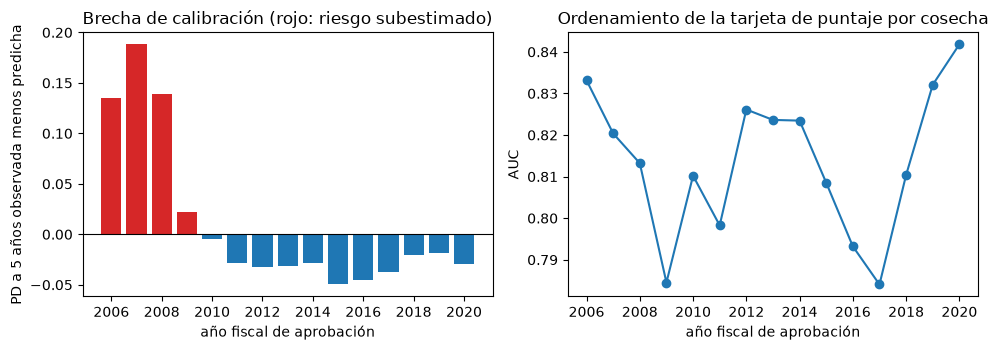

In [6]:
# Dibujar la brecha de calibración y el AUC de cada cosecha
years = [v["fiscal_year"] for v in vintages]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.bar(years, [v["gap"] for v in vintages], color=["tab:red" if v["gap"] > 0 else "tab:blue" for v in vintages])
left.axhline(0, color="black", linewidth=0.8)
left.set_xlabel("año fiscal de aprobación")
left.set_ylabel("PD a 5 años observada menos predicha")
left.set_title("Brecha de calibración (rojo: riesgo subestimado)")
right.plot(years, [v["auc"] for v in vintages], marker="o")
right.set_xlabel("año fiscal de aprobación")
right.set_ylabel("AUC")
right.set_title("Ordenamiento de la tarjeta de puntaje por cosecha")
fig.tight_layout()
plt.show()


### Paso 4: las curvas acumuladas por mes

Una cosecha no es un número sino una curva: la proporción acumulada de la cosecha castigada en los meses 12, 24, 36, 48 y 60. El modelo predice la curva completa y el archivo la observa. Una curva correcta en el mes 60 y errada en su forma seguiría siendo engañosa para una estimación de vida completa. La siguiente celda imprime el último punto de cada cosecha de la cohorte FY2008-10 (los años de la crisis) y de FY2015-17, y la figura dibuja sus curvas, predichas frente a observadas.

FY2008 mes 60: predicha 0.0735 | observada 0.2127
FY2009 mes 60: predicha 0.0615 | observada 0.0838
FY2010 mes 60: predicha 0.0541 | observada 0.0490
FY2015 mes 60: predicha 0.0882 | observada 0.0385
FY2016 mes 60: predicha 0.0836 | observada 0.0387
FY2017 mes 60: predicha 0.0804 | observada 0.0431


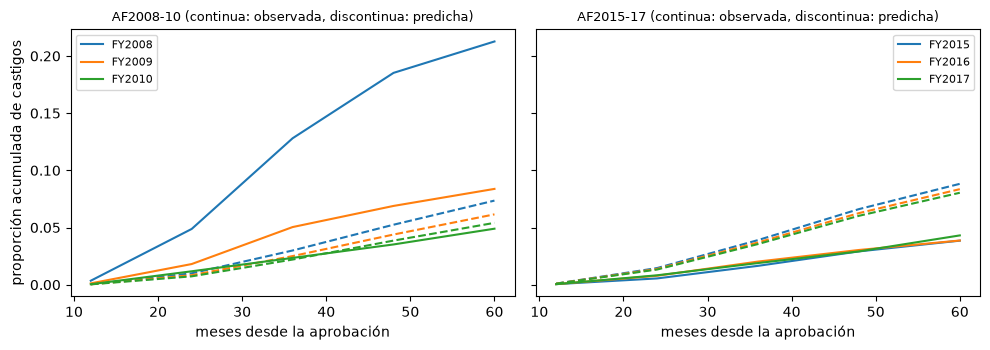

In [7]:
# Imprimir las curvas de la cohorte de la crisis y de FY2015-17 y dibujarlas, predichas frente a observadas
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, name in zip(axes, ("fy2008-10", "fy2015-17")):
    for curve in cohorts[name]["outputs"]["vintage_curves"]:
        line, = ax.plot(curve["months"], curve["predicted_cumulative_pd"], linestyle="--")
        ax.plot(curve["months"], curve["observed_cumulative_pd"], color=line.get_color(), label=f"FY{curve['fiscal_year']}")
        print(f"FY{curve['fiscal_year']} mes {curve['months'][-1]}: predicha {curve['predicted_cumulative_pd'][-1]:.4f} | observada {curve['observed_cumulative_pd'][-1]:.4f}")
    ax.set_title(cohorts[name]["outputs"]["cohort"]["label"][LANG] + " (continua: observada, discontinua: predicha)", fontsize=9)
    ax.set_xlabel("meses desde la aprobación")
    ax.legend(fontsize=8)
axes[0].set_ylabel("proporción acumulada de castigos")
fig.tight_layout()
plt.show()


### Paso 5: la batería de cada cohorte, recalculada

Cada archivo de cohorte versiona la batería del motor sobre la tarjeta de puntaje (escalón P1), con una fila de portafolio por prueba y una fila por cosecha para las pruebas de nivel. El portafolio de una cohorte tiene $N$ créditos, $D$ castigos y una PD predicha media; los resúmenes de cosecha de arriba contienen los tres, así que el motor puede llamarse sobre ellos y compararse con las filas versionadas. La siguiente celda reconstruye $N$, $D$ y la PD media de cada cohorte desde sus cosechas, llama a la prueba de Jeffreys y a la binomial ajustada por Vasicek (correlación de activos 0,12, el supuesto de modelación que la fila versionada declara en sus notas), y compara ambos valores p con los versionados. Las pruebas son unilaterales: rechazan cuando los incumplimientos superan lo que permite la PD.

In [8]:
# Reconstruir N, D y la PD media de cada cohorte desde sus cosechas, llamar al motor y comparar con las filas versionadas
from riskvalidation.validation import pd_binomial_vasicek, pd_jeffreys

policy = rv.default_policy()


def portfolio_row(doc, test_id, model_id="P1-scorecard"):
    return next(t for t in doc["tests"] if t["test_id"] == test_id and t["model_id"] == model_id and t["segment"] == "portfolio")


print(f"{'cohorte':10s} {'N':>8s} {'D':>6s} {'PD media':>8s} {'tasa':>7s} {'p Jeffreys':>11s} {'versionado':>11s} {'p Vasicek':>10s} {'versionado':>11s}")
for n in names:
    rows = cohorts[n]["outputs"]["vintage_summary"]["rows"]
    total = sum(v["n"] for v in rows)
    n_events = sum(round(v["observed_5y_pd"] * v["n"]) for v in rows)
    mean_pd = sum(v["predicted_5y_pd"] * v["n"] for v in rows) / total
    jef = pd_jeffreys(n=total, d=n_events, pd=mean_pd, policy=policy, model_id="P1-scorecard", segment="portfolio")
    vas = pd_binomial_vasicek(n=total, d=n_events, pd=mean_pd, rho=0.12, policy=policy, model_id="P1-scorecard", segment="portfolio")
    assert (portfolio_row(cohorts[n], "pd.jeffreys")["n"], portfolio_row(cohorts[n], "pd.jeffreys")["n_events"]) == (total, n_events)
    print(f"{n:10s} {total:8d} {n_events:6d} {mean_pd:8.4f} {n_events / total:7.4f} {jef.p_value:11.4f} {portfolio_row(cohorts[n], 'pd.jeffreys')['p_value']:11.4f} {vas.p_value:10.4f} {portfolio_row(cohorts[n], 'pd.binomial_vasicek')['p_value']:11.4f}")


cohorte           N      D PD media    tasa  p Jeffreys  versionado  p Vasicek  versionado
fy2006-07    174527  43581   0.0878  0.2497      0.0000      0.0000     0.0154      0.0154
fy2008-10    138023  18108   0.0647  0.1312      0.0000      0.0000     0.0845      0.0845
fy2011-14    170795   5790   0.0640  0.0339      1.0000      1.0000     0.7222      0.7222
fy2015-17    168203   6745   0.0840  0.0401      1.0000      1.0000     0.7841      0.7841
fy2018-20    136291   5256   0.0607  0.0386      1.0000      1.0000     0.6446      0.6446


Ahora la batería completa de la tarjeta de puntaje, cohorte por cohorte: el valor p de cada prueba y su luz. Lee la tabla como lo haría quien valida: no fila por fila sino columna por columna, preguntando a qué cohortes objeta la batería.

In [9]:
# Imprimir las filas de portafolio de la batería de la tarjeta de puntaje para las cinco cohortes
ids = ["disc.auc_vs_initial", "pd.jeffreys", "pd.binomial", "pd.binomial_vasicek", "pd.hosmer_lemeshow", "pd.spiegelhalter", "stability.psi"]
print(f"{'test':22s}" + "".join(f"{n:>18s}" for n in names))
for test_id in ids:
    line = f"{test_id:22s}"
    for n in names:
        row = portfolio_row(cohorts[n], test_id)
        line += f"{row['p_value']:12.3g} {LIGHT[row['light']]:>5s}"
    print(line)


test                           fy2006-07         fy2008-10         fy2011-14         fy2015-17         fy2018-20
disc.auc_vs_initial              1 verde           1 verde       0.977 verde    1.03e-08  rojo       0.468 verde
pd.jeffreys                      0  rojo           0  rojo           1 verde           1 verde           1 verde
pd.binomial                      0  rojo           0  rojo           1 verde           1 verde           1 verde
pd.binomial_vasicek         0.0154 ámbar      0.0845 verde       0.722 verde       0.784 verde       0.645 verde
pd.hosmer_lemeshow               0  rojo           0  rojo           0  rojo           0  rojo           0  rojo
pd.spiegelhalter                 0  rojo           0  rojo           1 verde           1 verde           1 verde
stability.psi                    0  rojo           0  rojo           0  rojo           0  rojo           0  rojo


Dos lecturas de esta tabla importan. Primero, las **pruebas unilaterales solo rechazan una subestimación**. Desde FY2011 la tarjeta de puntaje sobrepredice (la brecha es negativa), así que las pruebas de Jeffreys, binomial y Spiegelhalter tienen valores p cercanos a 1 y siguen en verde. Eso es correcto para lo que preguntan: no afirman que la PD sea correcta, solo que los incumplimientos no están por encima de ella. Un banco que valide solo con pruebas de nivel pasaría por alto una sobreestimación que inmoviliza capital. Segundo, la **prueba de ajuste bilateral, Hosmer-Lemeshow, es roja en todas las cohortes**, y también el PSI. El AUC contra desarrollo es rojo solo para FY2015-17. La siguiente celda recalcula ese estadístico desde los extras versionados, como en el cuaderno 03: el AUC de desarrollo y su varianza, el AUC de la cohorte y su varianza, y el valor p unilateral.

In [10]:
# Recalcular el AUC contra desarrollo de cada cohorte desde los extras versionados
print(f"{'cohorte':10s} {'AUC en desarrollo':>20s} {'AUC ahora':>9s} {'z recalculado':>14s} {'p recalculado':>14s} {'p versionado':>14s}")
for n in names:
    row = portfolio_row(cohorts[n], "disc.auc_vs_initial")
    e = row["extras"]
    z = (e["auc_initial"] - e["auc_current"]) / np.sqrt(e["s2_total"])
    print(f"{n:10s} {e['auc_initial']:20.4f} {e['auc_current']:9.4f} {z:14.3f} {stats.norm.sf(z):14.3g} {row['p_value']:14.3g}")


cohorte       AUC en desarrollo AUC ahora  z recalculado  p recalculado   p versionado
fy2006-07                0.7967    0.8252         -4.626              1              1
fy2008-10                0.7832    0.8149         -4.800              1              1
fy2011-14                0.8042    0.8170         -1.998          0.977          0.977
fy2015-17                0.8226    0.7935          5.606       1.03e-08       1.03e-08
fy2018-20                0.8268    0.8264          0.080          0.468          0.468


### Paso 6: calibración por decil

El portafolio esconde dónde se equivoca el modelo. La calibración versionada agrupa los créditos de una cohorte en diez deciles de PD y da, para cada uno, la PD predicha, la tasa observada y un intervalo del 95% de la tasa observada. La siguiente celda cuenta en cuántos deciles la PD predicha cae fuera del intervalo de lo observado, para cada cohorte, y la figura dibuja los deciles de FY2015-17 en un eje logarítmico, donde la PD predicha de los deciles más bajos es varias veces lo observado.

fy2006-07  deciles: 10 | predicha sobre el intervalo: 0 | predicha bajo él: 10
fy2008-10  deciles: 10 | predicha sobre el intervalo: 2 | predicha bajo él: 6
fy2011-14  deciles: 10 | predicha sobre el intervalo: 9 | predicha bajo él: 0
fy2015-17  deciles: 10 | predicha sobre el intervalo: 9 | predicha bajo él: 1
fy2018-20  deciles: 10 | predicha sobre el intervalo: 8 | predicha bajo él: 2


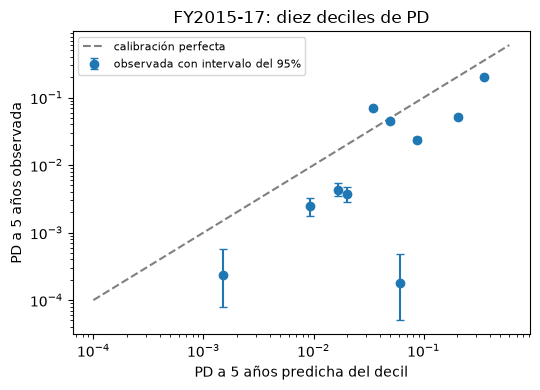

In [11]:
# Contar los deciles cuya PD predicha cae fuera del intervalo de la tasa observada, y dibujar FY2015-17
for n in names:
    rows = cohorts[n]["outputs"]["calibration"]["rows"]
    above = sum(r["predicted_pd"] > r["ci_high"] for r in rows)
    below = sum(r["predicted_pd"] < r["ci_low"] for r in rows)
    print(f"{n:10s} deciles: {len(rows)} | predicha sobre el intervalo: {above} | predicha bajo él: {below}")

rows = cohorts["fy2015-17"]["outputs"]["calibration"]["rows"]
predicted = np.array([r["predicted_pd"] for r in rows])
observed = np.array([max(r["observed_pd"], 1e-5) for r in rows])
low = np.array([max(r["ci_low"], 1e-5) for r in rows])
high = np.array([r["ci_high"] for r in rows])
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.errorbar(predicted, observed, yerr=[observed - low, high - observed], fmt="o", capsize=3, label="observada con intervalo del 95%")
ax.plot([1e-4, 0.6], [1e-4, 0.6], color="gray", linestyle="--", label="calibración perfecta")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("PD a 5 años predicha del decil")
ax.set_ylabel("PD a 5 años observada")
ax.set_title("FY2015-17: diez deciles de PD")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


### Paso 7: la escalera frente a la tarjeta de puntaje

Los archivos de cohorte también versionan el AUC de los seis modelos en cada cohorte. La siguiente celda los pone lado a lado. Un retador merece consideración solo si ordena mejor fuera del tiempo, no solo en los años de entrenamiento, y las cohortes son donde eso se decide.

In [12]:
# Imprimir el AUC de cada modelo en cada cohorte (el escalón TabPFN se declara ausente)
rung_ids = [r["rung_id"] for r in fit["ladder"]]
print(f"{'modelo':14s}" + "".join(f"{n:>12s}" for n in names))
for rung in rung_ids:
    line = f"{rung:14s}"
    for n in names:
        row = next(r for r in cohorts[n]["outputs"]["rung_comparison"] if r["rung_id"] == rung)
        line += f"{row['auc']:12.4f}"
    print(line)
absent = [r["rung_id"] for r in cohorts[names[0]]["outputs"]["rung_comparison"] if r["auc"] is None]
print("escalones sin número, declarados ausentes:", absent)


modelo           fy2006-07   fy2008-10   fy2011-14   fy2015-17   fy2018-20
P0-constant         0.5000      0.5000      0.5000      0.5000      0.5000
P1-scorecard        0.8252      0.8149      0.8170      0.7935      0.8264
P2a-l1              0.8264      0.8137      0.8355      0.8055      0.8341
P2b-pltr            0.7696      0.7748      0.8139      0.8489      0.7393
P3-ebm              0.7340      0.7769      0.8277      0.7951      0.7460
P4-lightgbm         0.7967      0.8323      0.8732      0.8367      0.8305
escalones sin número, declarados ausentes: ['P5-tabpfn']


## Resultados

- **El diseño es a prueba de fuga en las fechas.** Las cinco ventanas cierran en la marca de 5 años de su último año de entrenamiento, entre 2005-09-30 y 2017-09-30, y cada una cierra antes de la primera aprobación de su cohorte de prueba. Las cosechas no tienen ningún crédito censurado, porque cada una se lee en su marca de 5 años; la proporción de créditos aún activos tras 60 meses (hasta 29% en FY2018-20) se cuenta como no evento, lo que es correcto para un objetivo definido en el mes 60.
- **La calibración deriva por cohorte, y mucho.** Los créditos aprobados entre 2006 y 2008 se castigaron entre 21% y 28% en cinco años, frente a 7% a 9% predicho: las cohortes que atraviesan la crisis quedan fuertemente subpredichas (brecha de hasta +0,19) incluso para un modelo entrenado hasta 2002. Desde FY2011 la brecha cambia de signo y la tarjeta de puntaje sobrepredice entre 2 y 5 puntos, porque las ventanas de entrenamiento contienen los resultados de la crisis (FY2015-17 se entrena con 1991 a 2009) mientras que los créditos posteriores se comportaron mucho mejor.
- **La batería lee las dos direcciones de forma distinta.** Para las cohortes de la crisis las pruebas de Jeffreys y binomial son rojas. Para FY2011-14, FY2015-17 y FY2018-20 son verdes, con valores p cercanos a 1, porque solo preguntan si los incumplimientos superan la PD; Hosmer-Lemeshow y el PSI son rojos en las cinco, y el AUC contra desarrollo es rojo solo para FY2015-17 (0,823 en desarrollo, 0,793 ahora). Los valores p de Jeffreys y de Vasicek recalculados son iguales a los versionados.
- **Los deciles dicen dónde.** En la cohorte FY2015-17 los deciles más bajos están predichos varias veces sobre lo observado, y el intervalo de la tasa observada excluye la PD predicha en los diez deciles (nueve sobre él, uno bajo él), que es la imagen de un modelo que aprendió un mundo más riesgoso.
- **El ordenamiento es más robusto que el nivel.** El AUC de la tarjeta de puntaje por cosecha se mantiene entre 0,78 y 0,84 en las quince cosechas, mientras que el nivel se mueve decenas de puntos. Los modelos más ricos (árboles penalizados, LightGBM) ordenan mejor fuera del tiempo en FY2015-17 (0,849 y 0,837 frente a 0,793), aunque no en todas las cohortes (los árboles penalizados y la máquina de boosting ordenan por debajo de la tarjeta de puntaje en FY2018-20), y ninguno repara el nivel.

Lo que este cuaderno no muestra: cómo se ajustan los modelos sobre la muestra estratificada de 40.000 créditos de cada ventana (`data-pipeline/pipeline/cases/c03/fit.py` del pipeline), ni la dinámica de la recesión dentro de una cosecha. El archivo SBA es un programa federal, no la cartera pyme de un banco; las filas de cohorte son evidencia sobre este programa, no una afirmación sobre la cartera pyme de ningún banco. El escalón TabPFN se declara ausente, y ningún número lo reemplaza.

## Resumen

- Un panel se valida fuera del tiempo: cosechas por año fiscal de aprobación, ventanas de entrenamiento que cierran en una marca de 5 años antes de que empiece la cohorte de prueba, y un objetivo leído solo donde cada crédito ha tenido sus 60 meses.
- La calibración de una tarjeta de puntaje se mueve por cohorte: fuertemente subpredicha en la crisis, sobrepredicha después cuando la ventana de entrenamiento contenía la crisis.
- Las pruebas de nivel unilaterales rechazan solo una subestimación; leer un modelo solo por sus luces pasa por alto la sobreestimación, que muestran Hosmer-Lemeshow, la brecha de calibración y los deciles.
- El ordenamiento se sostiene mejor que el nivel, y los retadores se juzgan en las cohortes, no en los años de entrenamiento.

**Qué probar después.** Compara la brecha de FY2008-10 con un modelo entrenado después de la crisis, usando las ventanas de cohorte de `models-sba-7a.json`; luego continúa con el cuaderno 05, que aplica la misma disciplina a la PD corporativa a horizontes de uno a cinco años.

## Referencias

- U.S. Small Business Administration, 7(a) and 504 FOIA loan data (U.S. Government Works). https://data.sba.gov/dataset/7a-504-foia
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, secciones 2.5.3.1 y 2.5.4.1 y Anexo 1 (sección 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revisado): las pruebas binomial y binomial ajustada por Vasicek. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Yurdakul, B. y Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- Este repositorio: `docs/design/SDD.md` (la división a prueba de fuga de C03) y `data-pipeline/pipeline/cases/c03/`.